<a href="https://colab.research.google.com/github/elvira123-hub/Machine_Learning_Projects/blob/main/CuHe_NN_potential_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural-network potential for Cu⁺–He (trained on your CCSD(T)/aug-cc-pVTZ data)

**AIM**

1. Collects the data from PES at the CCSD(T)/aug-cc-pVTZ, CCSD(T)/aug-cc-pVQZ, DLPNO-CCSD(T)/cc-pVTZ(cu-He: aug-cc-pVTZ) and MP2/def2-TZVPP level of theory. In addition, BSSE was considered.
2. Reproduces the Morse fits as a baseline at different level of theory.
3. Trains a small neural network (PyTorch) on the CCSD(T)/aug-cc-pVTZ curve. Two versions are compared:
   * **NN-plain**: input = r.
   * **NN-physical**: input = (r₀/r)⁴ and the output is shifted so that E(∞) = 0 to build in the ion–induced-dipole tail (−C₄/r⁴).
4. Compares the NN with other level of theory.


**Units**: r in Å, energies in kJ/mol (interaction energy, so E(∞) = 0).

## 1. Setup

In [8]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
np.random.seed(0)

# ---- physical constants / conversions ------------------------------------
KJ_TO_CM = 83.59347            # 1 kJ/mol in cm^-1
NA, AMU, C_CM = 6.02214076e23, 1.66053907e-27, 2.99792458e10
MU = (62.9295975 * 4.0026032) / (62.9295975 + 4.0026032)   # reduced mass 63Cu-4He, amu
print(f"reduced mass = {MU:.4f} amu")

reduced mass = 3.7632 amu


In [9]:
# ===================== CCSD(T)/aug-cc-pVTZ  (training data) =================
r_cc = np.array([1.698, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3,
                 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.0, 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9, 5.0])
E_cc = np.array([-1.014954579, -5.790182131, -7.743297541, -8.201015187, -7.903832689, -7.26145507,
                 -6.496787751, -5.725938483, -5.004295522, -4.353961745, -3.779857129, -3.278758479,
                 -2.844151272, -2.468717086, -2.145485007, -1.868204376, -1.631287028, -1.429584408,
                 -1.258204975, -1.112481166, -0.988083059, -0.88119197, -0.78862918, -0.707880772,
                 -0.637021441, -0.574582772, -0.519415451, -0.470579549, -0.427272583, -0.38879042,
                 -0.354510842, -0.323887377, -0.296447069, -0.271786561])   # kJ/mol
assert len(r_cc) == len(E_cc) == 34

# ===================== MP2/def2-TZVPP (reference method, 11 points) ==========
r_mp2 = np.array([1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8])
E_mp2 = np.array([-1.75619695, -4.0474708, -4.9474922, -5.07955485, -4.8135917, -4.38117185,
                  -3.9182962, -3.4887644, -3.10990475, -2.7762037, -2.478472])

# ===================== Morse parameters of the other methods ================
#   V(r) = De*(1-exp(-alpha*(r-re)))^2 - De      (De in kJ/mol, alpha in 1/A, re in A)
MORSE_PARAMS = {
    "CCSD(T)/aug-cc-pVQZ (Morse)":      dict(De=9.77,  alpha=2.05,  re=1.98),
    "DLPNO-CCSD(T)/TightPNO (Morse)":   dict(De=8.96,  alpha=2.32,  re=1.98),
    "BSSE, aug-cc-pVQZ (Morse)":        dict(De=8.44,  alpha=2.07,  re=2.00),
    "DLPNO-CCSD(T) aVQZ/C (Morse)":     dict(De=8.191, alpha=2.383, re=1.977),
}
def morse_V(r, De, alpha, re):
    return De * (1 - np.exp(-alpha * (r - re)))**2 - De

# ===================== choose the NN training set ===========================
USE_FULL_RANGE = True     # True : train on all 34 points (1.698-5.0 A)
                          # False: train only on the Morse-fit window 1.8-3.6 A (19 points)
win = (r_cc >= 1.8) & (r_cc <= 3.6)
train_mask = np.ones_like(r_cc, bool) if USE_FULL_RANGE else win
print("CCSD(T)/aVTZ points:", len(r_cc), "| used for final NN training:", train_mask.sum())

CCSD(T)/aVTZ points: 34 | used for final NN training: 34


## 3. Baseline: the Morse fits

Two Morse forms are fitted to the **1.8–3.6 Å window**

* `Morse3`: De·(e^(−2α(r−re)) − 2e^(−α(r−re))), tends to 0 at large r.
* `Morse4`: the same **minus an offset Do**, as in the notebook.

In [10]:
def morse3(r, De, alpha, re):
    return De * (np.exp(-2*alpha*(r-re)) - 2*np.exp(-alpha*(r-re)))
def morse4(r, De, alpha, re, Do):
    return morse3(r, De, alpha, re) - Do

p3, _ = curve_fit(morse3, r_cc[win], E_cc[win], p0=[9, 2, 2], maxfev=200000)
p4, _ = curve_fit(morse4, r_cc[win], E_cc[win], p0=[8.5, 2, 2, 1], maxfev=200000)
print("Morse3  De, alpha, re      =", np.round(p3, 4))
print("Morse4  De, alpha, re, Do  =", np.round(p4, 4), "   (V at r=inf is", round(-p4[3], 3), "kJ/mol)")

# MP2 curve: 3-parameter Morse fitted to its 11 points (as in your MP2 notebook)
p_mp2, _ = curve_fit(morse3, r_mp2, E_mp2, p0=[9, 2, 2], maxfev=200000)
print("MP2 Morse3 De, alpha, re   =", np.round(p_mp2, 4))

morse3_fn = lambda r: morse3(np.asarray(r, float), *p3)
morse4_fn = lambda r: morse4(np.asarray(r, float), *p4)
mp2_fn    = lambda r: morse3(np.asarray(r, float), *p_mp2)

Morse3  De, alpha, re      = [7.9507 1.8347 2.0173]
Morse4  De, alpha, re, Do  = [7.4535 2.1177 2.0085 0.6942]    (V at r=inf is -0.694 kJ/mol)
MP2 Morse3 De, alpha, re   = [5.0588 1.953  2.0995]


## 4. The neural network

* **For NN-plain**: the input is (r − 3)/1.5 and the output is E directly.
* ** For NN-physical**: the input is u = (r₀/r)⁴ with r₀ = 2 Å, and the output is **E(r) = g(u) − g(0)**. Because u → 0 as r → ∞, this forces E(∞) = 0 exactly. For large r, E ≈ g′(0)·u ∝ r⁻⁴, the ion–induced-dipole law.

**Training**: mean-squared error on energies (optionally plus the force term, see the docstring), first I used Adam with a cosine-decaying learning rate, then an L-BFGS polish.

In [11]:
import torch, torch.nn as nn
torch.set_default_dtype(torch.float64)
print("torch", torch.__version__)

class PES(nn.Module):
    '''E(r) for a diatomic. r is a tensor of shape (N,1) in Angstrom, output in kJ/mol.'''
    def __init__(self, mode="physical", hidden=32, r0=2.0, e_scale=1.0):
        super().__init__()
        self.mode, self.r0, self.e_scale = mode, r0, e_scale
        self.net = nn.Sequential(nn.Linear(1, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, 1))
    def features(self, r):
        if self.mode == "plain":
            return (r - 3.0) / 1.5
        return (self.r0 / r) ** 4                         # -> 0 as r -> infinity
    def forward(self, r):
        out = self.net(self.features(r))
        if self.mode == "physical":
            out = out - self.net(torch.zeros(1, 1))        # enforce E(infinity) = 0
        return self.e_scale * out

def fit_member(r, E, mode="physical", seed=0, dEdr=None, w_grad=1.0, hidden=32,
               adam_epochs=2000, lbfgs_iters=300, lr=5e-3):
    '''
    r, E   : numpy arrays (Angstrom, kJ/mol)
    dEdr   : optional numpy array of dE/dr (= -force along the bond, kJ/mol/A).
             If given, a force term is added to the loss (not used in this notebook's default data).'''
    torch.manual_seed(seed)
    e_scale = float(np.std(E))
    model = PES(mode, hidden, e_scale=e_scale)
    use_grad = dEdr is not None
    r_t = torch.tensor(np.asarray(r, float).reshape(-1, 1), requires_grad=use_grad)
    E_t = torch.tensor(np.asarray(E, float).reshape(-1, 1))
    if use_grad:
        G_t = torch.tensor(np.asarray(dEdr, float).reshape(-1, 1))

    def loss_fn():
        pred = model(r_t)
        loss = (((pred - E_t) / e_scale) ** 2).mean()
        if use_grad:
            g = torch.autograd.grad(pred.sum(), r_t, create_graph=True)[0]
            loss = loss + w_grad * (((g - G_t) / e_scale) ** 2).mean()
        return loss

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=adam_epochs, eta_min=1e-5)
    for _ in range(adam_epochs):
        opt.zero_grad(); loss_fn().backward(); opt.step(); sched.step()
    if lbfgs_iters:
        opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=lbfgs_iters,
                                line_search_fn="strong_wolfe",
                                tolerance_grad=1e-12, tolerance_change=1e-14)
        def closure():
            opt.zero_grad(); l = loss_fn(); l.backward(); return l
        opt.step(closure)
    model.eval()
    return model

def predict(model, r):
    '''numpy in, numpy out (kJ/mol).'''
    with torch.no_grad():
        return model(torch.tensor(np.asarray(r, float).reshape(-1, 1))).numpy().ravel()

torch 2.11.0+cu130


In [12]:
def fit_ensemble(r, E, mode, n=10, **kw):
    return [fit_member(r, E, mode, seed=s, **kw) for s in range(n)]

def predict_ens(models, r):
    P = np.array([predict(m, r) for m in models])
    return P.mean(0), P.std(0)

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2)))

## 5. Test A: extrapolation

* the **long-range tail**, 3.7–5.0 Å (14 points),
* the **repulsive wall** at 1.698 Å (1 point).


All values in kJ/mol


,RMSE on training window,RMSE on tail 3.7-5.0 A,error at 1.698 A,E at 8 A (should be ~0)
model,,,,
Morse3 (zero asymptote),0.180,0.265,-1.893,-0.000
"Morse4 (with offset, your fit)",0.053,0.313,-0.683,-0.694
NN-plain (ensemble mean),0.001,5.276,-0.788,45.424
NN-physical (ensemble mean),0.002,0.009,0.024,-0.038


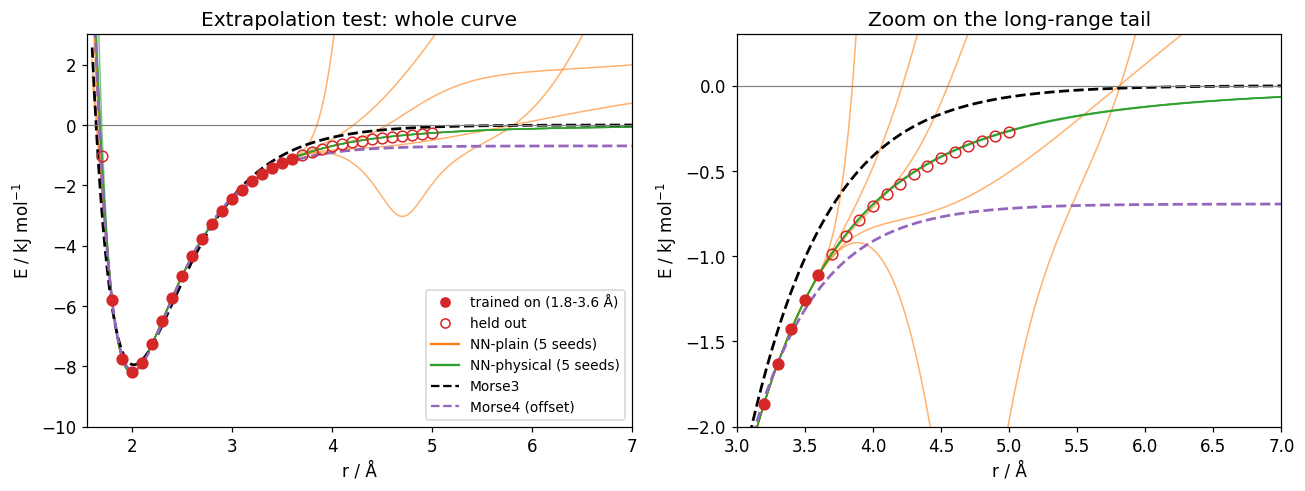

In [13]:
r_tr, E_tr = r_cc[win], E_cc[win]
r_tail, E_tail = r_cc[r_cc > 3.6], E_cc[r_cc > 3.6]
r_wall, E_wall = r_cc[r_cc < 1.8], E_cc[r_cc < 1.8]

ensA_plain = fit_ensemble(r_tr, E_tr, "plain",    n=5)
ensA_phys  = fit_ensemble(r_tr, E_tr, "physical", n=5)

def tail_report(name, f):
    return dict(model=name,
                RMSE_window=rmse(f(r_tr), E_tr),
                RMSE_tail_3p7_5p0=rmse(f(r_tail), E_tail),
                err_at_1p698=float(f(r_wall)[0] - E_wall[0]),
                E_at_8A=float(f(np.array([8.0]))[0]))
rows = [tail_report("Morse3 (zero asymptote)", morse3_fn),
        tail_report("Morse4 (with offset, your fit)", morse4_fn),
        tail_report("NN-plain (ensemble mean)", lambda r: predict_ens(ensA_plain, r)[0]),
        tail_report("NN-physical (ensemble mean)", lambda r: predict_ens(ensA_phys, r)[0])]
dfA = pd.DataFrame(rows).set_index("model")
dfA.columns = ["RMSE on training window", "RMSE on tail 3.7-5.0 A", "error at 1.698 A", "E at 8 A (should be ~0)"]
print("All values in kJ/mol")
display(dfA.round(3))

# ---- figure ---------------------------------------------------------------
rd = np.linspace(1.6, 7.0, 500)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, (ylo, yhi, xlo, xhi) in zip(ax, [(-10, 3, 1.55, 7.0), (-2.0, 0.3, 3.0, 7.0)]):
    for m in ensA_plain: a.plot(rd, predict(m, rd), color="tab:orange", lw=1, alpha=.6)
    for m in ensA_phys:  a.plot(rd, predict(m, rd), color="tab:green",  lw=1, alpha=.6)
    a.plot(rd, morse3_fn(rd), "k--", lw=1.8)
    a.plot(rd, morse4_fn(rd), color="tab:purple", ls="--", lw=1.8)
    a.plot(r_tr,   E_tr,   "o", color="tab:red", ms=7, zorder=5)
    a.plot(r_tail, E_tail, "o", mfc="none", mec="tab:red", ms=7, zorder=5)
    a.plot(r_wall, E_wall, "o", mfc="none", mec="tab:red", ms=7, zorder=5)
    a.axhline(0, color="gray", lw=.8)
    a.set_xlim(xlo, xhi); a.set_ylim(ylo, yhi)
    a.set_xlabel("r / Å"); a.set_ylabel("E / kJ mol$^{-1}$")
from matplotlib.lines import Line2D
ax[0].legend(handles=[
    Line2D([], [], marker="o", color="tab:red", ls="", label="trained on (1.8-3.6 Å)"),
    Line2D([], [], marker="o", mfc="none", mec="tab:red", ls="", label="held out"),
    Line2D([], [], color="tab:orange", label="NN-plain (5 seeds)"),
    Line2D([], [], color="tab:green",  label="NN-physical (5 seeds)"),
    Line2D([], [], color="k", ls="--", label="Morse3"),
    Line2D([], [], color="tab:purple", ls="--", label="Morse4 (offset)")], fontsize=9, loc="lower right")
ax[0].set_title("Extrapolation test: whole curve"); ax[1].set_title("Zoom on the long-range tail")
plt.tight_layout(); plt.show()

Each thin line is one network. If the NN-plain lines fan out in the tail while the NN-physical lines stay together and decay to zero, the physical input is doing its job. Morse4 goes to −Do instead of 0. At 1.698 Å (steep repulsive wall) **every** model is off by about 1 kJ/mol or more: no model can predict a wall it has never seen, so if you need short distances, compute points there.

## 6. Test B: interpolation
A network is trained on the remaining points (all 34 if `USE_FULL_RANGE`, else the window), and the removed point is predicted. A single network per fold with fewer epochs keeps this quick (~2–4 min). Set `RUN_LOO = False` to skip it.

NN-plain     LOO RMSE = 0.0116   max |err| = 0.0578 kJ/mol
NN-physical  LOO RMSE = 0.0115   max |err| = 0.0583 kJ/mol


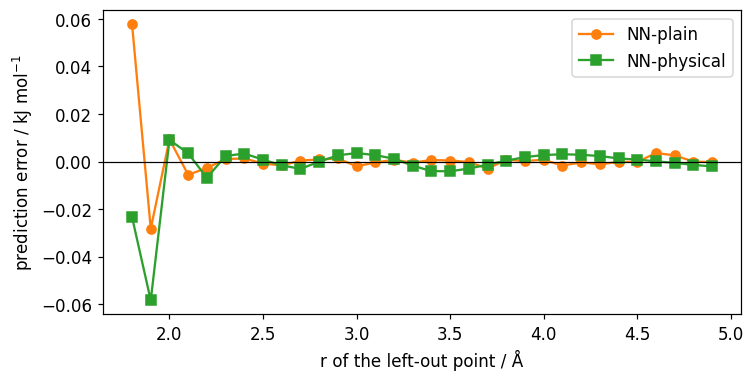

In [14]:
RUN_LOO = True
if RUN_LOO:
    r_loo, E_loo = r_cc[train_mask], E_cc[train_mask]
    fast = dict(adam_epochs=1500, lbfgs_iters=200)
    loo = {}
    for mode in ["plain", "physical"]:
        errs = []
        for i in range(1, len(r_loo) - 1):                  # interior points only
            keep = np.ones(len(r_loo), bool); keep[i] = False
            m = fit_member(r_loo[keep], E_loo[keep], mode, seed=0, **fast)
            errs.append(predict(m, r_loo[i:i+1])[0] - E_loo[i])
        loo[mode] = np.array(errs)
        print(f"NN-{mode:8s}  LOO RMSE = {rmse(loo[mode], 0):.4f}   max |err| = {np.abs(loo[mode]).max():.4f} kJ/mol")
    plt.figure(figsize=(7, 3.6))
    plt.plot(r_loo[1:-1], loo["plain"],    "o-", color="tab:orange", label="NN-plain")
    plt.plot(r_loo[1:-1], loo["physical"], "s-", color="tab:green",  label="NN-physical")
    plt.axhline(0, color="k", lw=.8); plt.xlabel("r of the left-out point / Å")
    plt.ylabel("prediction error / kJ mol$^{-1}$"); plt.legend(); plt.tight_layout(); plt.show()

## 7. Final NN, trained on all selected data
Ten networks of each type, trained on the points selected by `USE_FULL_RANGE`. Then, how well do they reproduce the training points, compared to the Morse fits?

Reproduction of the CCSD(T)/aug-cc-pVTZ points (kJ/mol); Morse fits were done on 1.8-3.6 A only


,RMSE 1.8-3.6 A,RMSE all 34 pts,max |error| all pts
model,,,
Morse3,0.1798,0.3904,1.8931
Morse4,0.0532,0.2361,0.6830
NN-plain,0.0008,0.0006,0.0016
NN-physical,0.0025,0.0022,0.0046


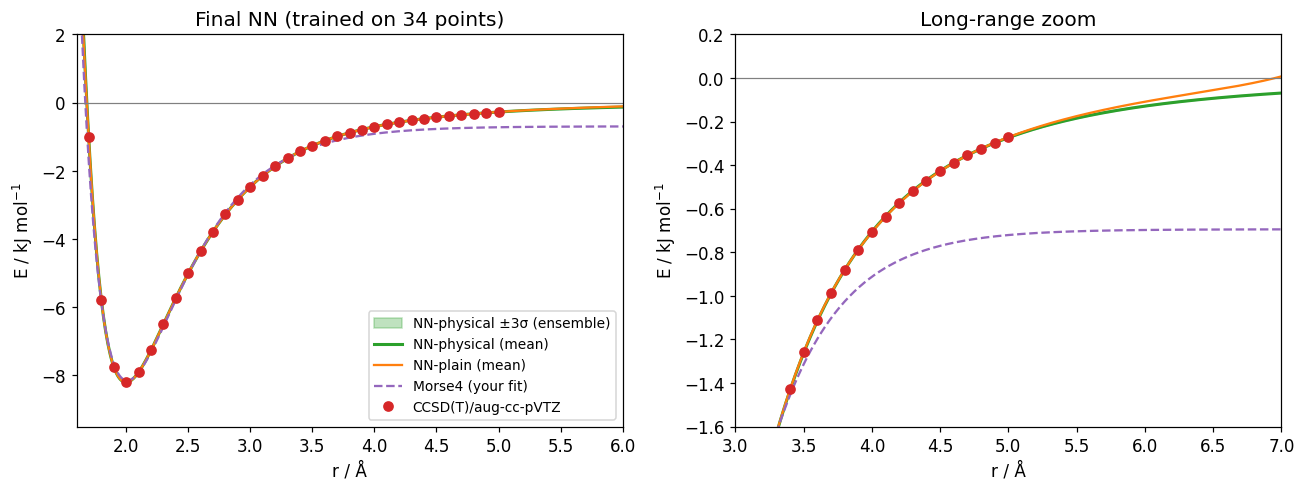

In [15]:
r_fin, E_fin = r_cc[train_mask], E_cc[train_mask]
ens_plain = fit_ensemble(r_fin, E_fin, "plain",    n=10)
ens_phys  = fit_ensemble(r_fin, E_fin, "physical", n=10)

nn_plain = lambda r: predict_ens(ens_plain, r)[0]
nn_phys  = lambda r: predict_ens(ens_phys,  r)[0]

fitq = []
for name, f in [("Morse3", morse3_fn), ("Morse4", morse4_fn), ("NN-plain", nn_plain), ("NN-physical", nn_phys)]:
    fitq.append(dict(model=name,
                     RMSE_window_1p8_3p6=rmse(f(r_cc[win]), E_cc[win]),
                     RMSE_all_34_points=rmse(f(r_cc), E_cc),
                     max_abs_err_all=float(np.abs(f(r_cc) - E_cc).max())))
dfq = pd.DataFrame(fitq).set_index("model")
dfq.columns = ["RMSE 1.8-3.6 A", "RMSE all 34 pts", "max |error| all pts"]
print("Reproduction of the CCSD(T)/aug-cc-pVTZ points (kJ/mol); Morse fits were done on 1.8-3.6 A only")
display(dfq.round(4))

rd = np.linspace(1.6, 7.0, 600)
mean, std = predict_ens(ens_phys, rd)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, (ylo, yhi, xlo, xhi) in zip(ax, [(-9.5, 2, 1.6, 6.0), (-1.6, 0.2, 3.0, 7.0)]):
    a.fill_between(rd, mean - 3*std, mean + 3*std, color="tab:green", alpha=.3, label="NN-physical ±3σ (ensemble)")
    a.plot(rd, mean, color="tab:green", lw=2, label="NN-physical (mean)")
    a.plot(rd, nn_plain(rd), color="tab:orange", lw=1.5, label="NN-plain (mean)")
    a.plot(rd, morse4_fn(rd), color="tab:purple", ls="--", lw=1.5, label="Morse4 (your fit)")
    a.plot(r_cc, E_cc, "o", color="tab:red", ms=6, label="CCSD(T)/aug-cc-pVTZ", zorder=5)
    a.axhline(0, color="gray", lw=.8); a.set_xlim(xlo, xhi); a.set_ylim(ylo, yhi)
    a.set_xlabel("r / Å"); a.set_ylabel("E / kJ mol$^{-1}$")
ax[0].legend(fontsize=9); ax[0].set_title("Final NN (trained on %d points)" % len(r_fin)); ax[1].set_title("Long-range zoom")
plt.tight_layout(); plt.show()

## 8. Comparison with the other quantum-chemistry levels

**8a. Spectroscopic quantities** from each curve: equilibrium distance rₑ, well depth Dₑ = −E(rₑ), and the harmonic frequency ωₑ computed from the curvature at the minimum with the ⁶³Cu–⁴He reduced mass. For the NN rows the ± is the spread of the ensemble.

**8b. Point-by-point difference** (method − NN-physical) on the shared grid 1.8–3.6 Å (MP2 only up to 2.8 Å, where you have points). A negative number means the method is *more binding* than the NN (which represents CCSD(T)/aug-cc-pVTZ).

,re / A,De / kJ/mol,De / cm-1,omega_e / cm-1
level,,,,
CCSD(T)/aVTZ: NN-physical (this work),1.999 ± 0.001,8.20 ± 0.00,686 ± 0,234 ± 2
CCSD(T)/aVTZ: NN-plain,1.999 ± 0.001,8.20 ± 0.00,685 ± 0,234 ± 2
CCSD(T)/aVTZ: Morse3 (your fit),2.017,7.95,665,200
CCSD(T)/aVTZ: Morse4 (your fit),2.008,8.15,681,224
MP2/def2-TZVPP (Morse fit to 11 pts),2.099,5.06,423,170
CCSD(T)/aug-cc-pVQZ (Morse),1.980,9.77,817,248
DLPNO-CCSD(T)/TightPNO (Morse),1.980,8.96,749,269
"BSSE, aug-cc-pVQZ (Morse)",2.000,8.44,706,233
DLPNO-CCSD(T) aVQZ/C (Morse),1.977,8.19,685,264


kJ/mol


,r range / A,RMSD vs NN,max |diff|,mean (method - NN)
method,,,,
CCSD(T)/aVTZ Morse4 (your fit),1.8-3.6,0.05,0.09,0.00
MP2/def2-TZVPP (raw points),1.8-2.8,2.48,4.03,2.25
CCSD(T)/aug-cc-pVQZ (Morse),1.8-3.6,0.92,2.03,-0.44
DLPNO-CCSD(T)/TightPNO (Morse),1.8-3.6,0.70,0.86,0.32
"BSSE, aug-cc-pVQZ (Morse)",1.8-3.6,0.38,0.53,0.18
DLPNO-CCSD(T) aVQZ/C (Morse),1.8-3.6,0.85,1.13,0.74


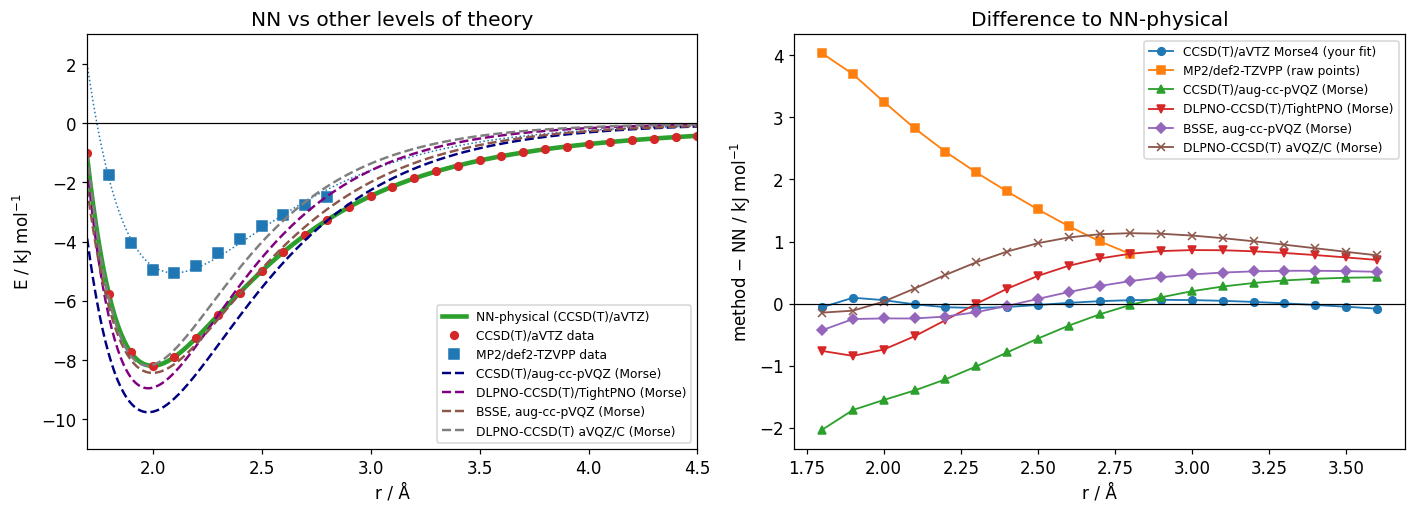

In [16]:
def spectro(E_fn, r_min=1.6, r_max=3.5, step=0.0005, h_idx=20):
    r = np.arange(r_min, r_max, step); E = E_fn(r)
    i = int(np.argmin(E)); h = h_idx * step
    k = (E[i + h_idx] - 2*E[i] + E[i - h_idx]) / h**2          # kJ/mol/A^2
    k_Nm = k * 1e3 / NA / 1e-20                                 # N/m
    omega = np.sqrt(k_Nm / (MU * AMU)) / (2*np.pi*C_CM)         # cm^-1
    return dict(re=r[i], De_kJ=-E[i], De_cm=-E[i]*KJ_TO_CM, omega=omega)

def spectro_ens(models):
    S = pd.DataFrame([spectro(lambda r, m=m: predict(m, r)) for m in models])
    return S.mean(), S.std()

rows = []
for name, ens in [("CCSD(T)/aVTZ: NN-physical (this work)", ens_phys), ("CCSD(T)/aVTZ: NN-plain", ens_plain)]:
    mu_, sd_ = spectro_ens(ens)
    rows.append({"level": name, "re / A": f"{mu_.re:.3f} ± {sd_.re:.3f}", "De / kJ/mol": f"{mu_.De_kJ:.2f} ± {sd_.De_kJ:.2f}",
                 "De / cm-1": f"{mu_.De_cm:.0f} ± {sd_.De_cm:.0f}", "omega_e / cm-1": f"{mu_.omega:.0f} ± {sd_.omega:.0f}"})
others = [("CCSD(T)/aVTZ: Morse3 (your fit)", morse3_fn), ("CCSD(T)/aVTZ: Morse4 (your fit)", morse4_fn),
          ("MP2/def2-TZVPP (Morse fit to 11 pts)", mp2_fn)]
others += [(k, (lambda r, p=p: morse_V(np.asarray(r, float), **p))) for k, p in MORSE_PARAMS.items()]
for name, fn in others:
    s = spectro(fn)
    rows.append({"level": name, "re / A": f"{s['re']:.3f}", "De / kJ/mol": f"{s['De_kJ']:.2f}",
                 "De / cm-1": f"{s['De_cm']:.0f}", "omega_e / cm-1": f"{s['omega']:.0f}"})
display(pd.DataFrame(rows).set_index("level"))

# ---------------- 8b: point-by-point differences ------------------------------
r_cmp = np.round(np.arange(1.8, 3.601, 0.1), 2)
ref = nn_phys(r_cmp)
curves = [("CCSD(T)/aVTZ Morse4 (your fit)", morse4_fn, 3.6),
          ("MP2/def2-TZVPP (raw points)", lambda r: np.interp(r, r_mp2, E_mp2), 2.8)]
curves += [(k, (lambda r, p=p: morse_V(np.asarray(r, float), **p)), 3.6) for k, p in MORSE_PARAMS.items()]
diff_rows, diffs = [], {}
for name, fn, rmax in curves:
    m = r_cmp <= rmax + 1e-9
    d = fn(r_cmp[m]) - ref[m]; diffs[name] = (r_cmp[m], d)
    diff_rows.append({"method": name, "r range / A": f"1.8-{rmax}", "RMSD vs NN": rmse(d, 0),
                      "max |diff|": float(np.abs(d).max()), "mean (method - NN)": float(d.mean())})
print("kJ/mol")
display(pd.DataFrame(diff_rows).set_index("method").round(2))

# ---------------- figure ----------------------------------------------------------------
rd = np.linspace(1.7, 4.5, 400)
mean, std = predict_ens(ens_phys, rd)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
a = ax[0]
a.fill_between(rd, mean - 3*std, mean + 3*std, color="tab:green", alpha=.3)
a.plot(rd, mean, color="tab:green", lw=3, label="NN-physical (CCSD(T)/aVTZ)")
a.plot(r_cc, E_cc, "o", color="tab:red", ms=5, label="CCSD(T)/aVTZ data")
a.plot(r_mp2, E_mp2, "s", color="tab:blue", ms=6, label="MP2/def2-TZVPP data")
a.plot(rd, mp2_fn(rd), color="tab:blue", lw=1, ls=":")
for (k, p), c in zip(MORSE_PARAMS.items(), ["navy", "purple", "tab:brown", "tab:gray"]):
    a.plot(rd, morse_V(rd, **p), color=c, ls="--", lw=1.6, label=k)
a.axhline(0, color="k", lw=.8); a.set_ylim(-11, 3); a.set_xlim(1.7, 4.5)
a.set_xlabel("r / Å"); a.set_ylabel("E / kJ mol$^{-1}$"); a.legend(fontsize=8, loc="lower right")
a.set_title("NN vs other levels of theory")
a = ax[1]
for (name, (rr, d)), mk in zip(diffs.items(), ["o", "s", "^", "v", "D", "x"]):
    a.plot(rr, d, marker=mk, ms=5, lw=1.2, label=name)
a.axhline(0, color="k", lw=.8); a.set_xlabel("r / Å"); a.set_ylabel("method − NN / kJ mol$^{-1}$")
a.set_title("Difference to NN-physical"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Potential

In [17]:
r_out = np.round(np.arange(1.60, 10.001, 0.01), 3)
m_, s_ = predict_ens(ens_phys, r_out)
pd.DataFrame({"r_Angstrom": r_out, "E_kJ_per_mol": m_, "E_std_kJ_per_mol": s_}).to_csv("CuHe_NN_physical_PES.csv", index=False)
torch.save({"mode": "physical", "state_dicts": [m.state_dict() for m in ens_phys],
            "e_scales": [m.e_scale for m in ens_phys], "r0": 2.0}, "CuHe_NN_physical_ensemble.pt")
print("saved: CuHe_NN_physical_PES.csv, CuHe_NN_physical_ensemble.pt")
try:
    from google.colab import files
    files.download("CuHe_NN_physical_PES.csv"); files.download("CuHe_NN_physical_ensemble.pt")
except Exception:
    pass

saved: CuHe_NN_physical_PES.csv, CuHe_NN_physical_ensemble.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Limits
* **A NN is not more accurate than its data.** It reproduces CCSD(T)/aug-cc-pVTZ. For a single 1-D curve with 34 smooth points, a spline plus an r⁻ⁿ tail would do as well; the applied NN could becomes worthwhile when more degrees of freedom (Cu⁺–He₂, Cu⁺–He_n, other ligands) or many elements are added.
* **Better reference data beats a better network.** Basically, to go beyond aVTZ: someone can compute CCSD(T) at aVQZ/aV5Z and extrapolate to the complete-basis limit. This is feasible for small systems. However, it is complicated for larger model systems with more that one intermolecular distance to capture.